<a href="https://colab.research.google.com/github/wageesha111/telco-churn-prediction/blob/main/Telco_Churn_Coursework.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Telco Customer Churn Prediction

**Goal**: Predict whether a customer will churn (leave the company) – Yes or No.

**Models**: K-Nearest Neighbours (KNN), Logistic Regression, Random Forest

**Notebook structure**

1.   Load the data
2.   Task 1 – Exploratory Data Analysis (EDA)


1.   Task 2 – Data preprocessing
2.   Task 2 – Model training (Experiment 1: default settings, Experiment 2: tuned settings)

1.   Task 2 – Model evaluation and comparison
2.   Task 3 – Ethics checks








## 0. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

import warnings
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

## 1. Load the dataset

In [2]:
# Option A: same dataset from IBM's public GitHub (no upload needed)
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

# Option B: uploaded Kaggle file
# df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Shape:", df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# Task 1 – Exploratory Data Analysis (EDA)
### 1.1 Basic information about the columns

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


**Observation:** *TotalCharges* is stored as text (object) even though it is a number.
This is a *structural error* – we will fix it in preprocessing.

In [4]:
# Convert TotalCharges to a number (blank strings become NaN) – needed for EDA as well
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


### 1.2 Missing values and duplicates

In [5]:
print("Missing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0])
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

Missing values per column:
TotalCharges    11
dtype: int64

Duplicate rows: 0
Duplicate customer IDs: 0


In [6]:
# Who are the customers with missing TotalCharges?
df[df["TotalCharges"].isnull()][["tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No
3331,0,19.85,NaN,No
3826,0,25.35,NaN,No
4380,0,20.00,NaN,No
5218,0,19.70,NaN,No
6670,0,73.35,NaN,No


**Observation:** Only 11 rows have a missing  **TotalCharges** , and all of them have **tenure = 0**
(brand new customers who have not been billed yet). There are no duplicate rows.

### 1.3 Target variable – class distribution

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64


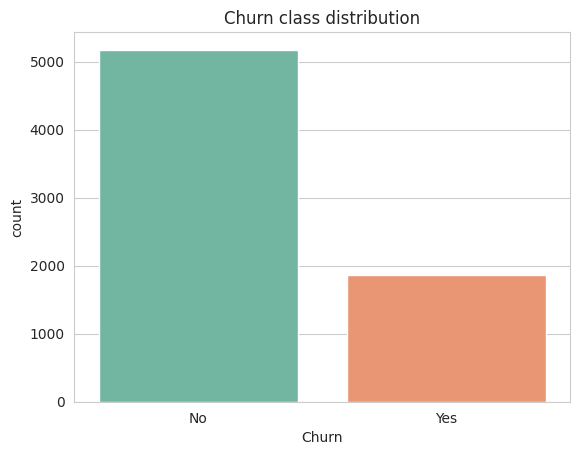

In [7]:
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True).round(3) * 100)

sns.countplot(x="Churn", data=df, palette="Set2")
plt.title("Churn class distribution")
plt.show()

**Observation:** About **73.5%** of customers did **not** churn and **26.5%** churned.
The dataset is **imbalanced**, so accuracy alone can be misleading. We will use **F1-score** and **Recall** as main metrics.

### 1.4 Numerical features vs Churn

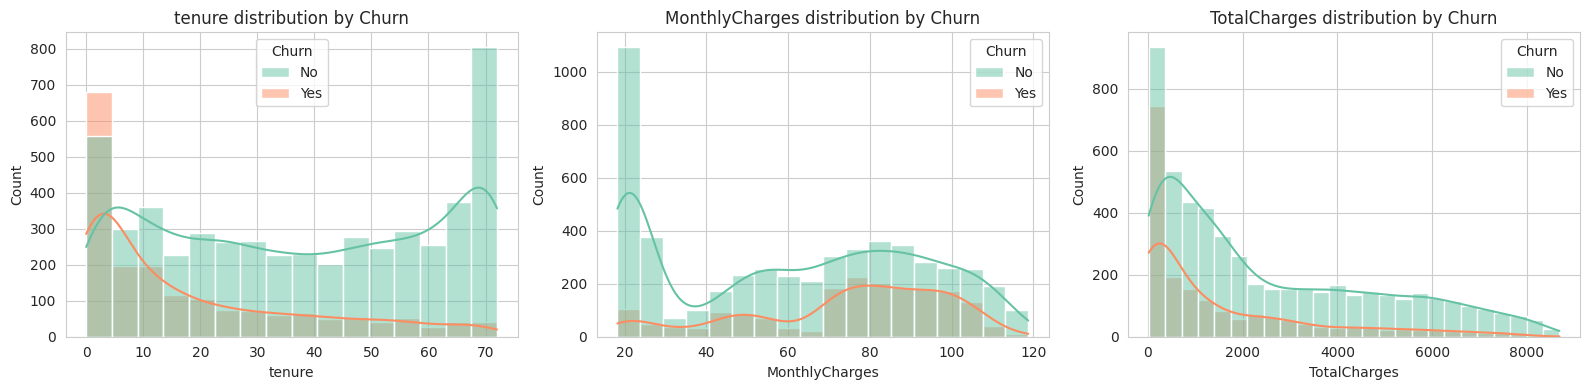

In [8]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for i, col in enumerate(num_cols):
    sns.histplot(data=df, x=col, hue="Churn", kde=True, ax=axes[i], palette="Set2")
    axes[i].set_title(col + " distribution by Churn")
plt.tight_layout()
plt.show()

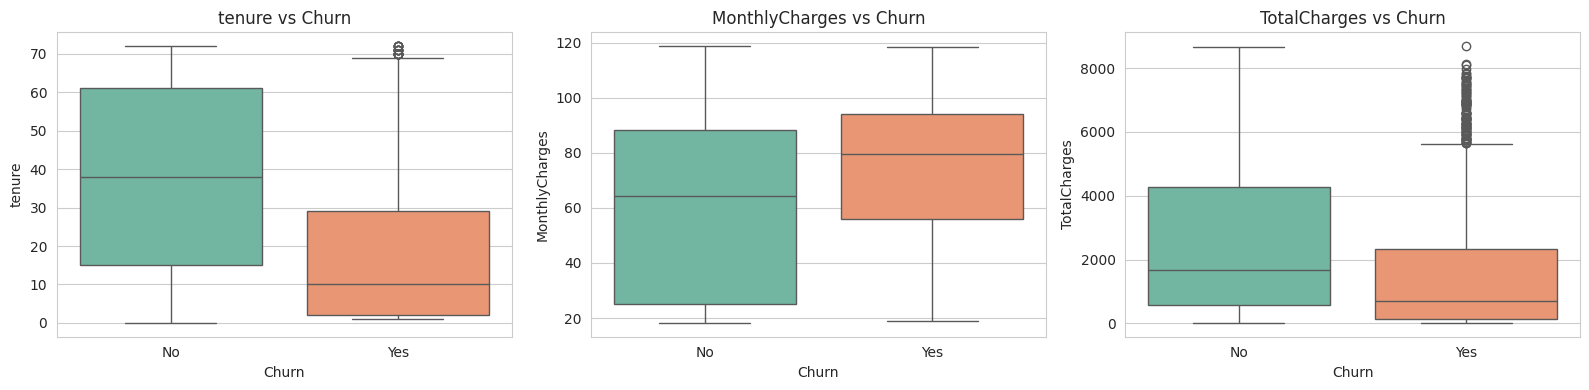

In [9]:
# Boxplots – to check outliers
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for i, col in enumerate(num_cols):
    sns.boxplot(data=df, x="Churn", y=col, ax=axes[i], palette="Set2")
    axes[i].set_title(col + " vs Churn")
plt.tight_layout()
plt.show()

In [10]:
# Outlier check using the IQR rule
for col in num_cols:
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = df[(df[col] < Q1 - 1.5 * IQR) | (df[col] > Q3 + 1.5 * IQR)]
    print(col, "-> outliers:", len(outliers))

tenure -> outliers: 0
MonthlyCharges -> outliers: 0
TotalCharges -> outliers: 0


**Observations:**
- Customers who churn have **low tenure** (most leave in the first few months).
- Churned customers have **higher monthly charges**.
- Churned customers have lower total charges (because they stay for a short time).
- No outliers were found using the IQR rule.

### 1.5 Categorical features vs Churn

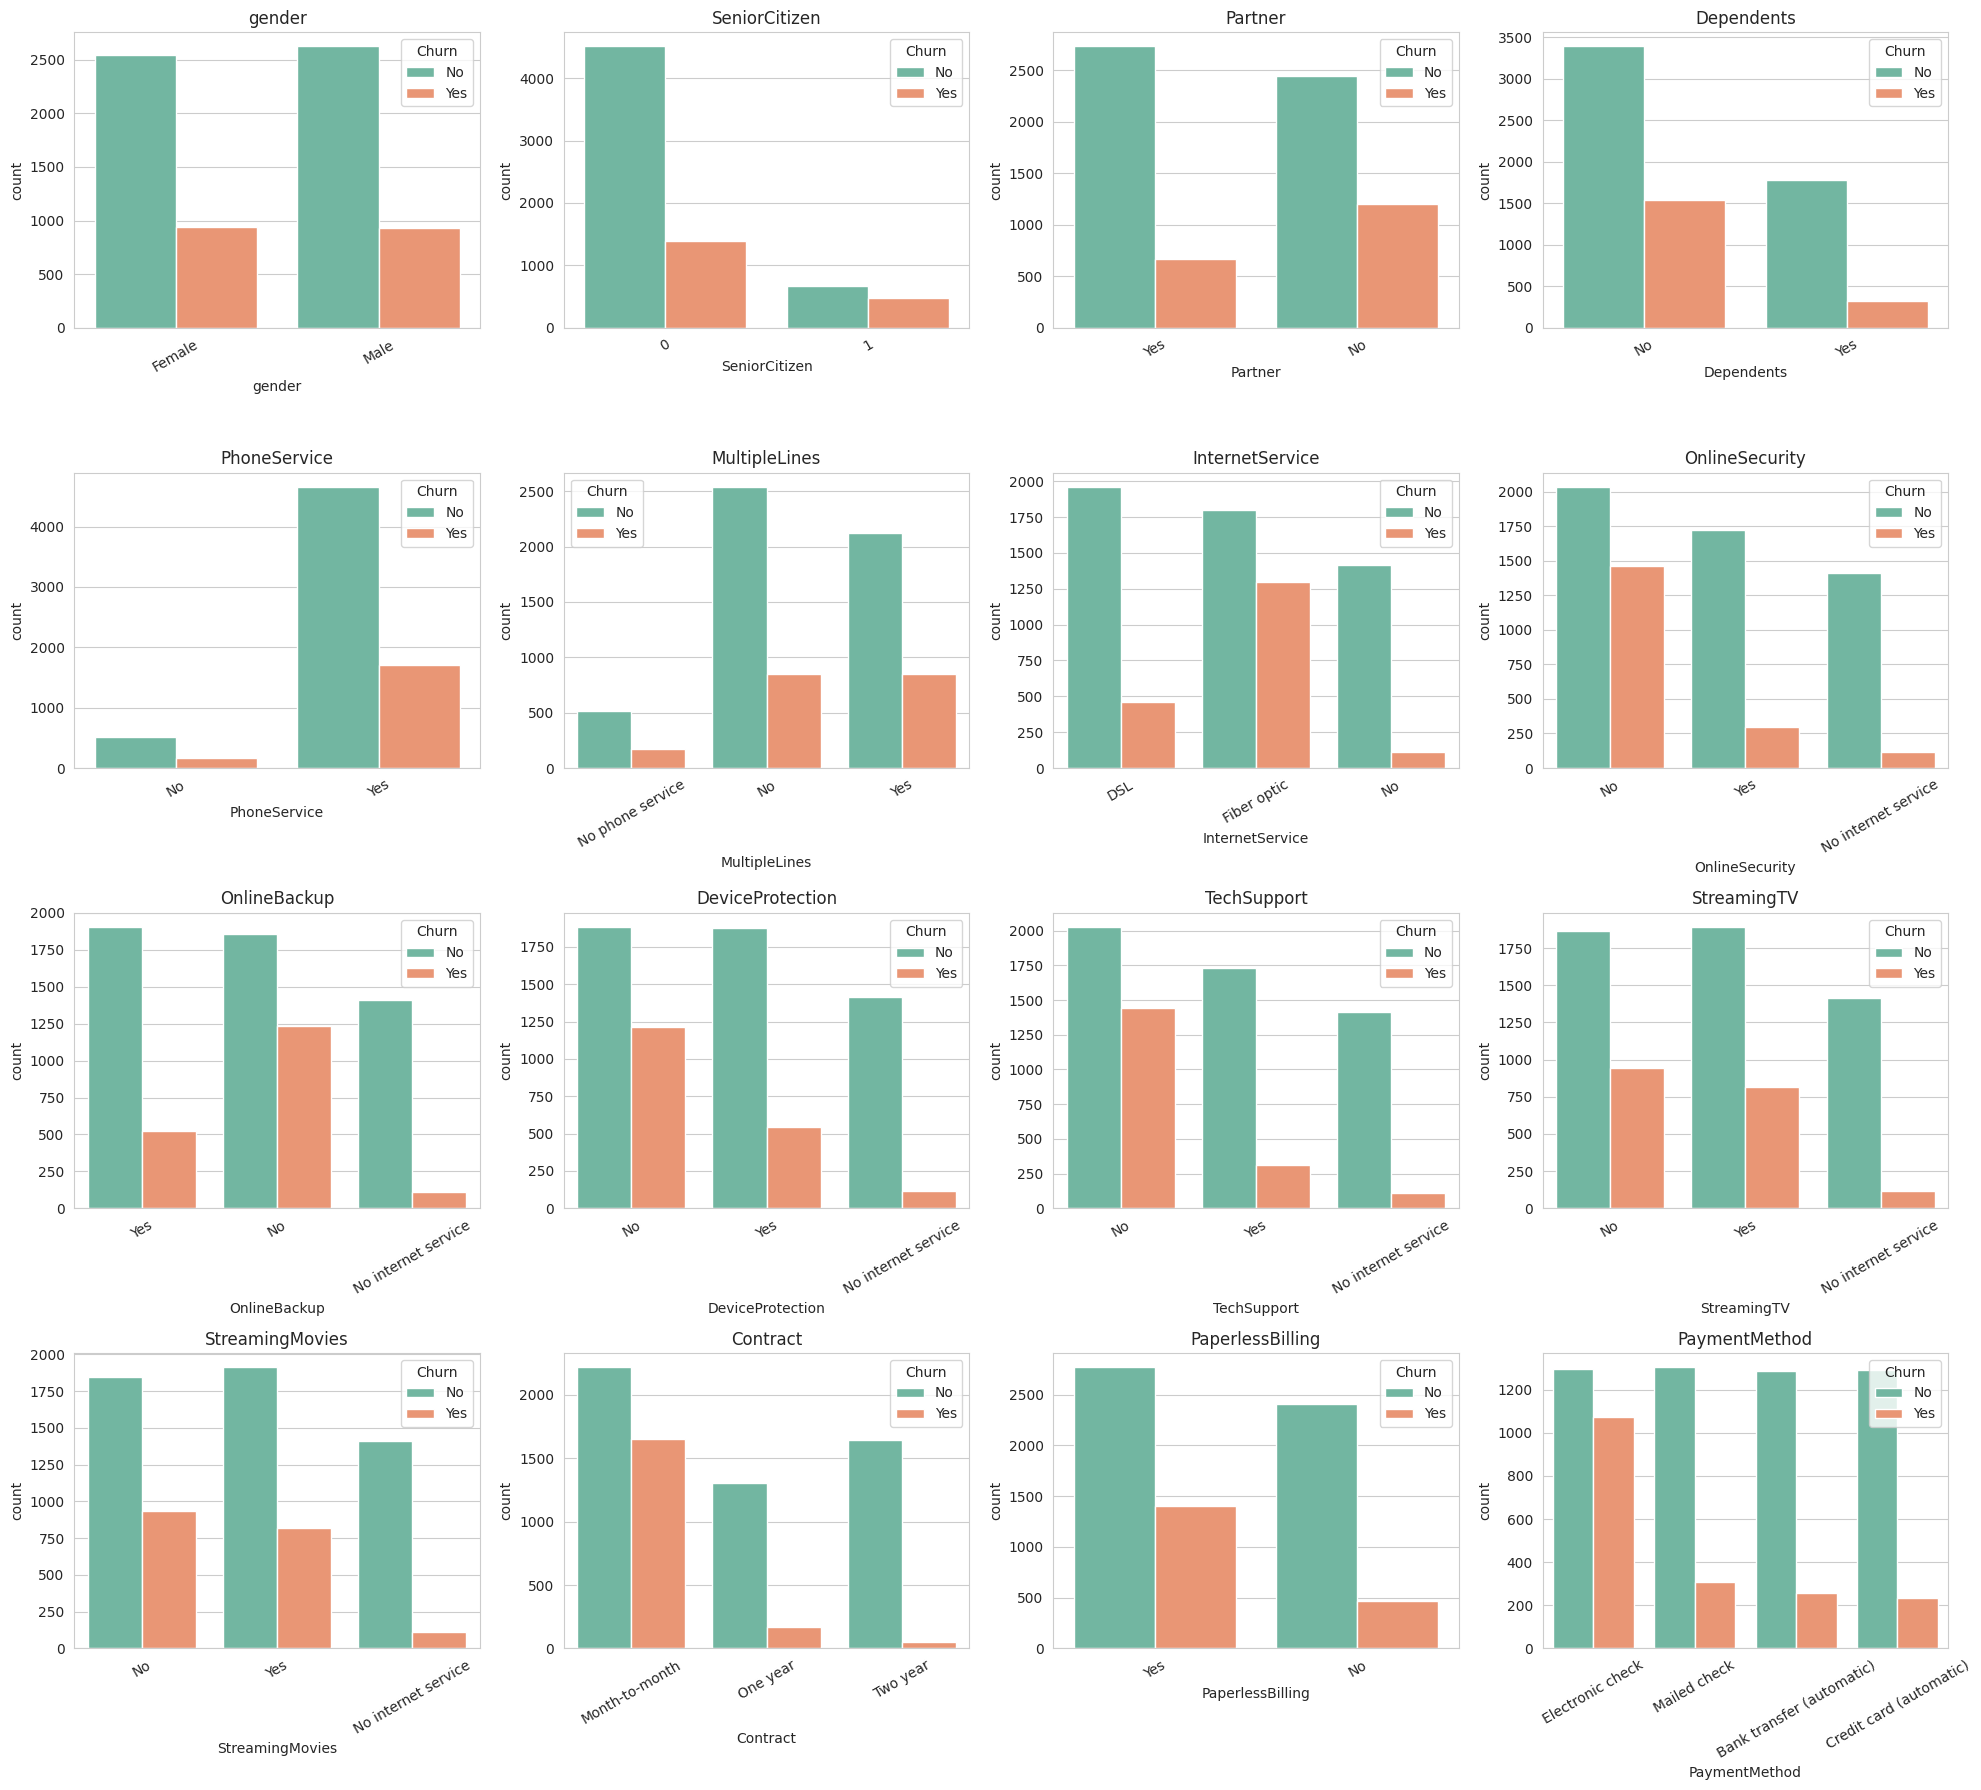

In [11]:
cat_cols = ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService",
            "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
            "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
            "Contract", "PaperlessBilling", "PaymentMethod"]

fig, axes = plt.subplots(4, 4, figsize=(20, 18))
axes = axes.flatten()
for i, col in enumerate(cat_cols):
    sns.countplot(data=df, x=col, hue="Churn", ax=axes[i], palette="Set2")
    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

In [12]:
# Churn rate (%) for the most important categorical columns
for col in ["Contract", "InternetService", "PaymentMethod", "TechSupport", "SeniorCitizen", "gender"]:
    rate = df.groupby(col)["Churn"].apply(lambda x: (x == "Yes").mean() * 100).round(1)
    print(rate, "\n")

Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: Churn, dtype: float64 

InternetService
DSL            19.0
Fiber optic    41.9
No              7.4
Name: Churn, dtype: float64 

PaymentMethod
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Electronic check             45.3
Mailed check                 19.1
Name: Churn, dtype: float64 

TechSupport
No                     41.6
No internet service     7.4
Yes                    15.2
Name: Churn, dtype: float64 

SeniorCitizen
0    23.6
1    41.7
Name: Churn, dtype: float64 

gender
Female    26.9
Male      26.2
Name: Churn, dtype: float64 



**Observations:**
- **Contract:** Month-to-month customers churn the most (~43%); two-year contract customers almost never churn (~3%).
- **Internet service:** Fiber optic users churn much more (~42%) than DSL users (~19%).
- **Payment method:** Electronic check users churn the most (~45%).
- **Tech support / Online security:** Customers *without* these services churn more.
- **Senior citizens** churn more (~42%) than non-seniors (~24%).
- **Gender** has almost no effect on churn (both ~26–27%).

### 1.6 Correlation between numerical features

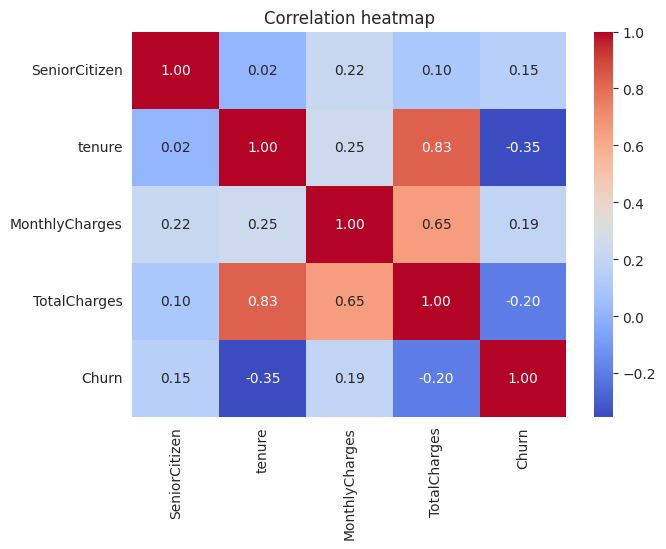

In [13]:
corr_df = df[["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]].copy()
corr_df["Churn"] = (df["Churn"] == "Yes").astype(int)

plt.figure(figsize=(7, 5))
sns.heatmap(corr_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation heatmap")
plt.show()

**Observations:**
- **tenure** has a negative correlation with churn (-0.35) → longer customers stay, less likely to leave.
- **MonthlyCharges** has a positive correlation with churn (+0.19).
- **TotalCharges** and **tenure** are strongly correlated (0.83) because TotalCharges ≈ tenure × MonthlyCharges.

# Task 2 – Data Preprocessing

1. Remove irrelevant columns
2. Fix structural errors
3. Check outliers (done in EDA – none found)
4. Handle missing data
5. Encode categorical data
6. Split into train / test sets
7. Scale (normalise) the features

In [14]:
data = df.copy()

# Step 1: Remove irrelevant column – customerID is just an ID, it does not help prediction
data = data.drop("customerID", axis=1)

# Step 2: Fix structural errors – "No internet service" / "No phone service" mean the same as "No"
data = data.replace({"No internet service": "No", "No phone service": "No"})

# Step 4: Handle missing data – only 11 rows (0.16%) have missing TotalCharges, so we drop them
data = data.dropna()
print("Shape after cleaning:", data.shape)

Shape after cleaning: (7032, 20)
